# Part 2 · A Vietnamese PDF knowledge base on Qdrant

Real documents are PDFs: scanned pages without text, tables that continue on the next page, several versions of the
same rule, and files not everyone may read. In this part you build a knowledge base for an agent that answers questions
about Vietnamese electricity prices, on a real **Qdrant** server running in Docker, and you look at it in the Qdrant
dashboard.

| Document (`data/pdfs/`) | Pages | PDF | In the lab |
|---|---|---|---|
| QĐ 2699/QĐ-BCT (2024), giá bán điện | 8 | scan | the **old** prices (household tier 1: 1.893 đ/kWh) |
| QĐ 1279/QĐ-BCT (2025), giá bán điện | 8 | scan | the **current** prices (tier 1: 1.984 đ/kWh) |
| QĐ 14/2025/QĐ-TTg, cơ cấu biểu giá bán lẻ điện | 7 | text layer | a 5-tier structure, in force but **not applied yet** |
| Gốm Minh An, dự toán chi phí điện 2026 | 1 | text layer | a **fictional** company's internal note, group `finance` only |

The three decisions are public legal documents (sources in `data/pdfs/SOURCES.md`). The internal note is a made-up
one-page document of group `finance`: it exists to show access control (step 6), a `public` user must never get it.
Code outside the notebook: `app/ingest.py` (pages → chunks) and `app/kb.py` (Qdrant).

**Before you start**: Docker installed and running, then in the session folder `docker compose up -d` (README, step 5).
Check with `docker compose ps` (status `Up`) or open the dashboard http://localhost:6333/dashboard.

In [1]:
import logging
import os
import time
from dataclasses import dataclass

from dotenv import load_dotenv

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
for noisy in ("httpx", "httpx2"):  # HTTP clients log every request at INFO
    logging.getLogger(noisy).setLevel(logging.WARNING)
logger = logging.getLogger(__name__)

load_dotenv()  # the .env of this session folder
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError("OPENAI_API_KEY is missing: copy .env.example to .env and fill it in (README, setup step 3).")
MODEL = os.getenv("MODEL", "openai:gpt-6-luna")
logger.info("Model: %s", MODEL)

from utils import log_call, short, stream, system_prompt, table  # helpers shared by both notebooks (adds app/ to the path)
import ingest  # app/ingest.py: PDF pages → markdown → chunks
import kb      # app/kb.py: the Qdrant collection and the searches

kb.check_server()  # fails with the start command when the container is not running
print("qdrant: ok")

INFO | Model: openai:gpt-6-luna


qdrant: ok


## 1. Which pages have a text layer?

A PDF made by a word processor contains text; a scanned PDF contains only page images, and `page.get_text()` returns
nothing. The ingest code routes each page ([PyMuPDF](https://pymupdf.readthedocs.io/en/latest/recipes-text.html)):
at least 50 characters of text → read the text (and the tables with `find_tables()`); otherwise → OCR.

In [2]:
import pymupdf

rows = []
for doc_id, doc in ingest.DOCS.items():
    with pymupdf.open(ingest.PDF_DIR / doc.file) as pdf:
        text_pages = [p.number + 1 for p in pdf if ingest.has_text_layer(p)]
        rows.append([doc_id, pdf.page_count, len(text_pages), pdf.page_count - len(text_pages), doc.access_group])
table(rows, ["doc_id", "pages", "text layer", "scanned → OCR", "access_group"])

doc_id       pages  text layer  scanned → OCR  access_group
qd2699       8      0           8              public      
qd1279       8      0           8              public      
qd14_2025    7      7           0              public      
minhan_2026  1      1           0              finance     


## 2. OCR a scanned page with the session model

Local OCR engines (Tesseract, PaddleOCR/RapidOCR) often lose Vietnamese diacritics (*Bậc* → *Bc*), which breaks
keyword search. Here the page image goes to the **session model** (a vision model) with the instruction "convert to
GitHub-flavoured Markdown, keep diacritics and numbers exactly" (`ingest.OCR_PROMPT`). One page costs a fraction of a
cent and takes 10 to 30 seconds, so `ingest.load_pages` sends the scanned pages of a document concurrently
(`model.batch`) and **caches** the result in `data/ocr/<doc>_p<N>.md`. The lab ships that cache (checked against the
scans), so the rest of the notebook runs without OCR costs.

Below: page 4 of QĐ 1279 (the household price table), OCR'd live and compared with the cached file.

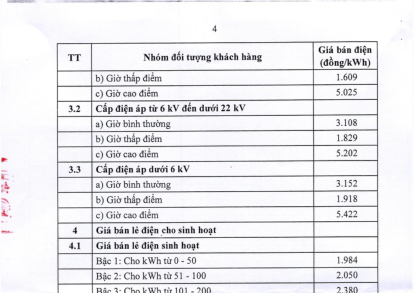

INFO | OCR of 1 page: 14 s


|  | Bậc 1: Cho kWh từ 0 - 50 | 1.984 |
|  | Bậc 2: Cho kWh từ 51 - 100 | 2.050 |
|  | Bậc 3: Cho kWh từ 101 - 200 | 2.380 |
|  | Bậc 4: Cho kWh từ 201 - 300 | 2.998 |
|  | Bậc 5: Cho kWh từ 301 - 400 | 3.350 |
|  | Bậc 6: Cho kWh từ 401 trở lên | 3.460 |
|  | Bậc 1: Cho kWh từ 0 - 50 | 1.658 |
|  | Bậc 2: Cho kWh từ 51 - 100 | 1.724 |
|  | Bậc 3: Cho kWh từ 101 - 200 | 1.876 |
|  | Bậc 4: Cho kWh từ 201 - 300 | 2.327 |
|  | Bậc 5: Cho kWh từ 301 - 400 | 2.635 |
|  | Bậc 6: Cho kWh từ 401 trở lên | 2.744 |

prices in the live OCR: 22, same as the cache: True


In [3]:
import re

from IPython.display import Image, display

pdf = pymupdf.open(ingest.PDF_DIR / ingest.DOCS["qd1279"].file)  # closed at the end of the cell
page = pdf[3]  # page 4
display(Image(page.get_pixmap(dpi=50, clip=pymupdf.Rect(0, 0, page.rect.width, page.rect.height / 2)).tobytes("png"),
              width=640))  # top half of the scan, small

started = time.monotonic()
live = ingest.ocr_images([ingest.page_png(page)])[0]  # not written to the cache
logger.info("OCR of 1 page: %.0f s", time.monotonic() - started)
print("\n".join(line for line in live.splitlines() if "Bậc" in line))  # the household tiers

cached = (ingest.OCR_DIR / "qd1279_p4.md").read_text(encoding="utf-8")
prices = lambda md: re.findall(r"\d\.\d{3}", md)  # prices such as 1.984
print(f"\nprices in the live OCR: {len(prices(live))}, same as the cache: {prices(live) == prices(cached)}")
pdf.close()

## 3. Table-aware chunks

`ingest.load_corpus()` reads every page (text layer or OCR cache) and cuts **section-based chunks**:
- prose by article (`Điều 1`, `Điều 2` …);
- price tables by section (`1.1`, `4.1`, `6.1.1` …), each table section **kept whole with its header row**, even when
  it continues on the next page; small tables without numbering stay inside their prose section;
- every chunk starts with the document title and a **breadcrumb** line `Mục: 3 Giá bán lẻ điện cho kinh doanh > 3.1 …`,
  so a chunk that only says "a) Giờ bình thường | 2.887" still says what it is about.

Section 3.1 of QĐ 1279 starts at the bottom of page 3 and continues at the top of page 4 (page 4 starts with the header
row and the rows `b)`, `c)`, no section name). The chunk below holds the three rows with the header and the breadcrumb.

<img src="images/b5_table_chunk.png" width="640">

A table that continues on the next page: every chunk repeats the header and the section path.

In [4]:
chunks = ingest.load_corpus()
logger.info("%d chunks", len(chunks))
table([[d, sum(c["doc_id"] == d for c in chunks)] for d in ingest.DOCS], ["doc_id", "chunks"])

example = next(c for c in chunks if c["doc_id"] == "qd1279" and c["section"].startswith("3.1 "))
print("\npayload:", {k: v for k, v in example.items() if k != "text"})
print(example["text"])

INFO | 95 chunks


doc_id       chunks
qd2699       33    
qd1279       33    
qd14_2025    24    
minhan_2026  5     

payload: {'doc_id': 'qd1279', 'title': 'Quyết định 1279/QĐ-BCT (2025) về giá bán điện', 'source_url': 'https://evn.com.vn/userfile/User/tcdl/files/2025/5/QD1279-QD-BCT-20250509163514982.pdf', 'page': 3, 'section': '3.1 Cấp điện áp từ 22 kV trở lên', 'effective_date': '2025-05-10T00:00:00Z', 'access_group': 'public'}
Quyết định 1279/QĐ-BCT (2025) về giá bán điện
Mục: 3 Giá bán lẻ điện cho kinh doanh > 3.1 Cấp điện áp từ 22 kV trở lên

| TT | Nhóm đối tượng khách hàng | Giá bán điện (đồng/kWh) |
|---|---|---|
| 3.1 | Cấp điện áp từ 22 kV trở lên |  |
|  | a) Giờ bình thường | 2.887 |
|  | b) Giờ thấp điểm | 1.609 |
|  | c) Giờ cao điểm | 5.025 |


## 4. The Qdrant collection

`kb.create_collection()` creates the collection `gia_dien` ([Qdrant collections](https://qdrant.tech/documentation/concepts/collections/)) with two **named vectors** per point:
- `dense`: 1536 numbers from `text-embedding-3-small`, cosine distance;
- `bm25`: a sparse vector computed **by the Qdrant server** from the text
  ([server-side BM25](https://qdrant.tech/documentation/inference/), `models.Document(text, model="qdrant/bm25")`),
  with `modifier=IDF`. Options `ascii_folding` (so `gia dien` matches `giá điện`) and no stopwords / stemmer
  (Vietnamese is not one of their languages: English stopwords would delete `thẻ` → `the`). The options must be the
  same when indexing and when querying.

[Payload indexes](https://qdrant.tech/documentation/concepts/indexing/#payload-index) on `doc_id`, `access_group`
(keyword), `effective_date` (datetime) and `page` (integer) make filters fast; they are created before the upsert.
Point ids are UUIDs derived from `doc_id#chunk number`, so running the ingest again overwrites instead of duplicating.

In [5]:
started = time.monotonic()
kb.create_collection()
kb.upsert_chunks(chunks)
logger.info("Collection %s built in %.1f s", kb.COLLECTION, time.monotonic() - started)

qc = kb.client()
info = qc.get_collection(kb.COLLECTION)
print("points:", qc.count(kb.COLLECTION).count)
print("vectors:", list(info.config.params.vectors), "+ sparse", list(info.config.params.sparse_vectors))
print("payload indexes:", {k: v.data_type.value for k, v in info.payload_schema.items()})
for group in ("public", "finance"):
    print(f"access_group={group}:", qc.count(kb.COLLECTION, count_filter=kb.access_filter([group])).count)

INFO | Collection gia_dien built in 3.9 s


points: 95
vectors: ['dense'] + sparse ['bm25']
payload indexes: {'access_group': 'keyword', 'effective_date': 'datetime', 'page': 'integer', 'doc_id': 'keyword'}
access_group=public: 90
access_group=finance: 5


Open the dashboard (http://localhost:6333/dashboard) → **Collections** → `gia_dien`: the points with their payload
(`doc_id`, `section`, `effective_date`, `access_group`, `text`), the collection info (two vectors, indexes) and the
**Visualize** tab (a 2-D map of the dense vectors).

<img src="images/qdrant_dashboard_points.png" width="640">

## 5. Dense vs BM25 vs hybrid on Vietnamese questions

`kb.hybrid_search` is one [Query API](https://qdrant.tech/documentation/concepts/hybrid-queries/) call: two
**prefetches** (dense top 20, BM25 top 20) fused with `FusionQuery(RRF)`, and the access filter at the top level (it
applies inside both prefetches). Ten questions with a known answer section, one without diacritics; for the price
tables both versions (2024 and 2025) count as a hit. **hit@1**: the right chunk is first. **MRR**: the mean of
1/rank of the first right chunk in the top 10 (1.0 = always first).

In [6]:
BCT = ("qd2699", "qd1279")
QUESTIONS = [  # (question, documents that hold the answer, section prefixes)
    ("Giá điện sinh hoạt bậc 1 từ 0 đến 50 kWh là bao nhiêu?", BCT, ("4.1",)),
    ("Nhà dùng công tơ thẻ trả trước thì giá điện bao nhiêu?", BCT, ("4.2",)),
    ("Giá điện giờ cao điểm cho nhà máy sản xuất cấp điện áp dưới 6 kV", BCT, ("1.4",)),
    ("Mức giá bán lẻ điện bình quân là bao nhiêu?", BCT, ("Điều 2",)),
    ("gia dien kinh doanh gio binh thuong cap dien ap duoi 6kV", BCT, ("3.3",)),  # no diacritics
    ("Theo cơ cấu mới, điện sinh hoạt chia thành mấy bậc?", ("qd14_2025",), ("4 ", "Điều 3")),
    ("Giá điện sạc xe điện được tính thế nào?", ("qd14_2025",), ("3.2",)),
    ("Hộ nghèo được hỗ trợ tiền điện bao nhiêu?", ("qd14_2025",), ("Điều 4",)),
    ("Cây sạc ô tô điện công cộng tính tiền điện ra sao?", ("qd14_2025",), ("3.2",)),
    ("Khi nào biểu giá 5 bậc bắt đầu được áp dụng?", ("qd14_2025",), ("Điều 6", "Điều 7")),
]
public = kb.access_filter(["public"])
RETRIEVERS = {
    "dense": lambda q: kb.dense_search(q, 10, public),
    "bm25": lambda q: kb.bm25_search(q, 10, public),
    "hybrid": lambda q: kb.hybrid_search(q, ["public"], k=10),
}


def rank_of_answer(points, docs, sections) -> int | None:
    return next((r for r, p in enumerate(points, 1)
                 if p.payload["doc_id"] in docs and p.payload["section"].startswith(sections)), None)


ranks = {name: [rank_of_answer(search(q), docs, secs) for q, docs, secs in QUESTIONS] for name, search in RETRIEVERS.items()}
table([[short(q, 52), *(ranks[n][i] or "-" for n in ranks)] for i, (q, _, _) in enumerate(QUESTIONS)],
      ["question (rank of the answer)", *ranks])


def scores(r: list) -> tuple[str, float]:
    return f"{sum(x == 1 for x in r)}/{len(r)}", round(sum(1 / x for x in r if x) / len(r), 2)


print()
table([[name, *scores(r)] for name, r in ranks.items()], ["retriever", "hit@1", "MRR"])

question (rank of the answer)                          dense  bm25  hybrid
Giá điện sinh hoạt bậc 1 từ 0 đến 50 kWh là bao nhiê…  3      2     2     
Nhà dùng công tơ thẻ trả trước thì giá điện bao nhiê…  1      1     1     
Giá điện giờ cao điểm cho nhà máy sản xuất cấp điện …  1      1     1     
Mức giá bán lẻ điện bình quân là bao nhiêu?            1      1     1     
gia dien kinh doanh gio binh thuong cap dien ap duoi…  1      1     1     
Theo cơ cấu mới, điện sinh hoạt chia thành mấy bậc?    1      1     1     
Giá điện sạc xe điện được tính thế nào?                9      1     1     
Hộ nghèo được hỗ trợ tiền điện bao nhiêu?              1      1     1     
Cây sạc ô tô điện công cộng tính tiền điện ra sao?     3      8     3     
Khi nào biểu giá 5 bậc bắt đầu được áp dụng?           3      -     4     

retriever  hit@1  MRR 
dense      6/10   0.71
bm25       7/10   0.76
hybrid     7/10   0.81


On this corpus BM25 is strong: legal text and price tables repeat the exact words of the questions. Dense search is
better on the everyday-language questions (*cây sạc ô tô điện công cộng*, *khi nào … bắt đầu được áp dụng*), where
BM25 ranks the answer low or misses it. Hybrid has the best MRR overall, without being the best on every question (a
rank can move by one between runs: API embeddings are not bit-identical every time).

The old and new price tables are near-duplicates, so a search often returns both: the tool returns 8 passages
(`kb.TOP_K`) so that the agent sees both versions and their dates.

## 6. The `search_kb` tool: access control from the runtime context

Who may read what is decided by the application, not by the model. The user's groups travel in the **runtime
context** ([LangChain runtime](https://docs.langchain.com/oss/python/langchain/runtime)): the agent is created with
`context_schema=UserContext`, each call passes `context=UserContext(...)`, and the tool reads `runtime.context`.
`ToolRuntime` is hidden from the model, so the model cannot pass or change the groups: they are not a tool argument.
The filter goes into every Qdrant query (`kb.access_filter`). Each passage starts with a citation label
`[title | trang N | hiệu lực YYYY-MM-DD]`.

<img src="images/b5_filters_split.png" width="640">

The model fills content filters; the app adds the access filter from the runtime context.

In [7]:
from langchain.tools import ToolRuntime, tool


@dataclass
class UserContext:
    user_id: str
    access_groups: list[str]


@tool(parse_docstring=True)
def search_kb(query: str, runtime: ToolRuntime[UserContext], effective_after: str | None = None) -> str:
    """Search the document collection (electricity price decisions, internal notes) with hybrid search.

    Returns the best passages, each with a citation label [title | trang N | hiệu lực YYYY-MM-DD].

    Args:
        query: What to look for, in Vietnamese, e.g. "giá điện sinh hoạt bậc 1".
        effective_after: Optional date YYYY-MM-DD; only documents that took effect on or after that date.
    """
    started = time.monotonic()
    text = kb.search_text(query, runtime.context.access_groups, effective_after)  # a bad date comes back as text
    log_call("search_kb", f"{query!r}, after={effective_after}, user={runtime.context.user_id}", "ok", started)
    return text

## 7. The Deep Agent

Same shared prompt as notebook 01 ([`prompts/system_prompt.md`](../prompts/system_prompt.md)): answer only from the
search results, cite the label, prefer the document that applies today and mention the replaced value, notice a
structure that is in force but not applied yet, and say when there is not enough evidence.
Two users: **An** (`public`) and **Bình** (`public`, `finance`).

In [8]:
from deepagents import create_deep_agent
from langchain.chat_models import init_chat_model

agent = create_deep_agent(model=init_chat_model(MODEL), tools=[search_kb], system_prompt=system_prompt(),
                          context_schema=UserContext)
an = UserContext(user_id="an", access_groups=["public"])
binh = UserContext(user_id="binh", access_groups=["public", "finance"])

**Two versions of the same table.** The 2024 and 2025 decisions give different tier-1 prices; the answer should give
the 2025 value and say that the 2024 value was replaced.

<img src="images/b5_conflict.png" width="640">

In [9]:
question = "Giá điện sinh hoạt bậc 1 hiện nay là bao nhiêu, và đã thay đổi so với năm 2024 chưa?"
answer = stream(agent, question, context=an)

Q: Giá điện sinh hoạt bậc 1 hiện nay là bao nhiêu, và đã thay đổi so với năm 2024 chưa?
→ search_kb({"query": "Giá điện sinh hoạt bậc 1 hiện nay và năm 2024, mức giá đồng/kWh, quyết định giá bán lẻ điện", "effe…)


INFO | search_kb('Giá điện sinh hoạt bậc 1 hiện nay và năm 2024, mức giá đồng/kWh, quyết định giá…) -> ok 204 ms


← search_kb success: [Quyết định 2699/QĐ-BCT (2024) về giá bán điện | trang 4 | hiệu lực 2024-10-11] Mục: 4 Giá bán lẻ điện cho sin…
Giá điện sinh hoạt bậc 1 hiện nay là **1.984 đồng/kWh** cho 50 kWh đầu tiên.[Quyết định 1279/QĐ-BCT (2025) về giá bán điện | trang 4 | hiệu lực 2025-05-10] Có, giá đã tăng **91 đồng/kWh** so với mức **1.893 đồng/kWh** áp dụng từ năm 2024.[Quyết định 1279/QĐ-BCT (2025) về giá bán điện | trang 4 | hiệu lực 2025-05-10][Quyết định 2699/QĐ-BCT (2024) về giá bán điện | trang 4 | hiệu lực 2024-10-11] Mức cũ 1.893 đồng/kWh theo Quyết định 2699/QĐ-BCT (2024) đã được thay thế.


**In force, not applied yet.** QĐ 14/2025 (newer than QĐ 1279) defines 5 household tiers, but its Điều 6 and 7 say it
applies only from the next adjustment of the average price. The prices in the collection still have 6 tiers.

In [10]:
question = "Giá điện sinh hoạt có mấy bậc?"
answer = stream(agent, question, context=an)

Q: Giá điện sinh hoạt có mấy bậc?
→ search_kb({"query": "Biểu giá bán lẻ điện sinh hoạt có mấy bậc giá điện sinh hoạt các bậc", "effective_after": null})


INFO | search_kb('Biểu giá bán lẻ điện sinh hoạt có mấy bậc giá điện sinh hoạt các bậc', after=No…) -> ok 298 ms


← search_kb success: [Quyết định 2699/QĐ-BCT (2024) về giá bán điện | trang 4 | hiệu lực 2024-10-11] Mục: 5 Giá bán buôn điện nông …
→ search_kb({"query": "Quyết định 14/2025/QĐ-TTg Điều 5 áp dụng kể từ cơ cấu biểu giá 5 bậc thời điểm áp dụng", "effective…)


INFO | search_kb('Quyết định 14/2025/QĐ-TTg Điều 5 áp dụng kể từ cơ cấu biểu giá 5 bậc thời điểm …) -> ok 257 ms


← search_kb success: [Quyết định 14/2025/QĐ-TTg về cơ cấu biểu giá bán lẻ điện | trang 5 | hiệu lực 2025-05-29] Mục: Phụ lục Phụ lụ…
Hiện biểu giá điện sinh hoạt đang áp dụng có **6 bậc**, từ bậc 1 (0–50 kWh) đến bậc 6 (từ 401 kWh trở lên). [Quyết định 1279/QĐ-BCT (2025) về giá bán điện | trang 4 | hiệu lực 2025-05-10] Quyết định mới quy định cơ cấu 5 bậc, nhưng sẽ được áp dụng từ lần điều chỉnh giá bán lẻ điện bình quân gần nhất sau khi quyết định có hiệu lực; tài liệu tìm được chưa cho thấy điều kiện này đã xảy ra, và quy định chuyển tiếp giữ cơ cấu cũ đến lúc đó. [Quyết định 14/2025/QĐ-TTg về cơ cấu biểu giá bán lẻ điện | trang 4 | hiệu lực 2025-05-29]


**Access control.** The same question from An (`public`) and from Bình (`finance`). The internal note never reaches
An's search results, whatever the model asks.

In [11]:
question = "Ngân sách điện năm 2026 của Gốm Minh An là bao nhiêu?"
for user in (an, binh):
    print(f"── user {user.user_id} {user.access_groups}")
    answer = stream(agent, question, context=user)

── user an ['public']
Q: Ngân sách điện năm 2026 của Gốm Minh An là bao nhiêu?
→ search_kb({"query": "Ngân sách điện năm 2026 của Gốm Minh An", "effective_after": null})


INFO | search_kb('Ngân sách điện năm 2026 của Gốm Minh An', after=None, user=an) -> ok 325 ms


← search_kb success: [Quyết định 14/2025/QĐ-TTg về cơ cấu biểu giá bán lẻ điện | trang 3 | hiệu lực 2025-05-29] Mục: Điều 4 Điều 4.…
→ search_kb({"query": "Gốm Minh An ngân sách điện 2026 dự toán chi phí điện", "effective_after": null})


INFO | search_kb('Gốm Minh An ngân sách điện 2026 dự toán chi phí điện', after=None, user=an) -> ok 202 ms


← search_kb success: [Quyết định 2699/QĐ-BCT (2024) về giá bán điện | trang 5 | hiệu lực 2024-10-11] Mục: 6 Giá bán buôn điện khu t…
→ search_kb({"query": "Minh An electricity budget 2026 forecast budget", "effective_after": null})


INFO | search_kb('Minh An electricity budget 2026 forecast budget', after=None, user=an) -> ok 223 ms


← search_kb success: [Quyết định 2699/QĐ-BCT (2024) về giá bán điện | trang 5 | hiệu lực 2024-10-11] Mục: 6 Giá bán buôn điện khu t…
Các tài liệu tìm được không có đủ thông tin để xác định ngân sách điện năm 2026 của Gốm Minh An. Cần có dự toán hoặc ghi chú nội bộ nêu ngân sách của doanh nghiệp, chẳng hạn số tiền dự kiến hay mức tiêu thụ điện và giả định giá áp dụng.
── user binh ['public', 'finance']
Q: Ngân sách điện năm 2026 của Gốm Minh An là bao nhiêu?
→ search_kb({"query": "Gốm Minh An ngân sách điện năm 2026 chi phí điện dự toán điện", "effective_after": null})


INFO | search_kb('Gốm Minh An ngân sách điện năm 2026 chi phí điện dự toán điện', after=None, use…) -> ok 219 ms


← search_kb success: [Gốm Minh An – Dự toán chi phí điện năm 2026 (nội bộ) | trang 1 | hiệu lực 2025-12-15] Mục: III. Tổng hợp III.…
Ngân sách điện năm 2026 đề nghị duyệt cho Gốm Minh An là **2.506.000.000 đồng, chưa gồm VAT**; con số này đã tính dự phòng 5% cho khả năng điều chỉnh giá điện. [Gốm Minh An – Dự toán chi phí điện năm 2026 (nội bộ) | trang 1 | hiệu lực 2025-12-15]


**Out of scope.** Nothing in the collection answers this: the agent should say so instead of answering from memory.

In [12]:
question = "Giá xăng RON 95 hiện nay là bao nhiêu?"
answer = stream(agent, question, context=an)

Q: Giá xăng RON 95 hiện nay là bao nhiêu?
→ search_kb({"query": "giá xăng RON 95 hiện nay giá bán lẻ xăng RON 95-III", "effective_after": null})


INFO | search_kb('giá xăng RON 95 hiện nay giá bán lẻ xăng RON 95-III', after=None, user=an) -> ok 233 ms


← search_kb success: [Quyết định 14/2025/QĐ-TTg về cơ cấu biểu giá bán lẻ điện | trang 3 | hiệu lực 2025-05-29] Mục: Điều 5 Điều 5.…
→ search_kb({"query": "RON95 xăng dầu mức giá điều hành giá xăng dầu kỳ điều hành", "effective_after": null})


INFO | search_kb('RON95 xăng dầu mức giá điều hành giá xăng dầu kỳ điều hành', after=None, user=a…) -> ok 274 ms


← search_kb success: [Quyết định 2699/QĐ-BCT (2024) về giá bán điện | trang 1 | hiệu lực 2024-10-11] Mục: Phần mở đầu BỘ CÔNG THƯƠN…
→ search_kb({"query": "xăng RON 95-III giá bán lẻ xăng dầu liên Bộ Công Thương Tài chính", "effective_after": null})


INFO | search_kb('xăng RON 95-III giá bán lẻ xăng dầu liên Bộ Công Thương Tài chính', after=None,…) -> ok 190 ms


← search_kb success: [Quyết định 2699/QĐ-BCT (2024) về giá bán điện | trang 4 | hiệu lực 2024-10-11] Mục: 3 Giá bán lẻ điện cho kin…
Các tài liệu hiện có không đủ thông tin để xác định giá xăng RON 95 hiện nay; kết quả tìm kiếm chỉ có tài liệu về giá điện, không có mức giá xăng RON 95.


## 8. Optional: rerank the hybrid results with the model

A **reranker** reads the question and each candidate together and orders them again; it is slower than the first
retrieval, so it runs only on the top 20. Dedicated cross-encoders exist (for example `BAAI/bge-reranker-v2-m3`,
a 570 MB download, about 5 s per 20 passages on a laptop CPU); here the session model does it, with structured output
([LangChain structured output](https://docs.langchain.com/oss/python/langchain/structured-output)), so nothing is
downloaded. Same ten questions as step 5.

In [13]:
from pydantic import BaseModel, Field


class Ranking(BaseModel):
    ids: list[int] = Field(description="Passage ids from most to least useful to answer the question (best 5).")


reranker = init_chat_model(MODEL).with_structured_output(Ranking)


def rerank(question: str, points) -> list:
    listing = "\n\n".join(f"[{i}] {p.payload['text'][:600]}" for i, p in enumerate(points))
    ids = reranker.invoke(f"Question: {question}\n\nRank the passages by how well they answer the question.\n\n{listing}").ids
    ids = [i for i in dict.fromkeys(ids) if 0 <= i < len(points)]  # keep valid, unique ids
    return [points[i] for i in ids] + [p for i, p in enumerate(points) if i not in ids]


started = time.monotonic()
ranks["hybrid + rerank"] = [rank_of_answer(rerank(q, kb.hybrid_search(q, ["public"], k=20)), docs, secs)
                            for q, docs, secs in QUESTIONS]
logger.info("Reranked %d questions in %.0f s", len(QUESTIONS), time.monotonic() - started)
table([[name, *scores(r)] for name, r in ranks.items()], ["retriever", "hit@1", "MRR"])

INFO | Reranked 10 questions in 52 s


retriever        hit@1  MRR 
dense            6/10   0.71
bm25             7/10   0.76
hybrid           7/10   0.81
hybrid + rerank  10/10  1.0 


## 9. Optional extension: the same search as an MCP server

`app/kb_mcp_server.py` serves `search_kb` with [FastMCP](https://gofastmcp.com/), so Claude, Cursor or another agent
can use this knowledge base. The access groups are fixed when the server starts (`--groups`), never by the model.
With `--public` it also opens an [ngrok](https://ngrok.com/docs/getting-started/python/) https URL for apps outside
this machine (claude.ai, a teammate's Cursor) and then requires the API key `KB_READ_KEY` from `.env` on every request
(`Authorization: Bearer …`); keep the default `--groups public` on a public server.
Steps and host configs for Claude, Cursor and Claude Code: [docs/02_mcp_server.md](../docs/02_mcp_server.md).
Run it in a terminal (it keeps running):

In [14]:
# In a terminal opened in the session folder (UV_PROJECT_ENVIRONMENT=venvAE05):
#   uv run app/kb_mcp_server.py --http --groups public    # Streamable HTTP on localhost, one log line per search
#   uv run app/kb_mcp_server.py --http --public           # plus a public https URL (needs NGROK_AUTHTOKEN, KB_READ_KEY)
# Do not point the generic `mcp-server-qdrant` at this collection: it expects its own vector name and payload keys.

**What to remember**
- Parse by page type: text layer → PyMuPDF (+ tables), scan → OCR with a vision model, cached.
- Chunk by structure: whole table sections with header and breadcrumb beat fixed-size pieces.
- One Qdrant collection, two named vectors, RRF in one Query API call; same BM25 options at index and query time.
- Access control and dates are payload filters set by the application (runtime context), not tool arguments.
- The prompt makes the agent cite, prefer the version that applies today, and say when evidence is missing.

When you are done: `docker compose down` (the data stays in the Docker volume; `docker compose down -v` deletes it).